# Fake Job Postings — Exploratory Data Analysis
**Project:** End-to-end NLP + Machine Learning pipeline to detect fraudulent job postings from their text and metadata.

**This notebook covers:**
1. Dataset at a glance
2. Class balance
3. Missing data
4. Strongest signals (binary, categorical, industry / function / country)
5. Text findings (length, discriminative words)
6. Data quality issues (duplicates, salary format, dollar amounts, ghost-company signal)
7. Suggested next steps

> Place `fake_job_postings.csv` in the same folder as this notebook (or edit `PATH` below).

In [367]:
import re
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer 
import warnings
import warnings
warnings.filterwarnings('ignore')
import joblib 

%matplotlib inline
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)

PATH = "fake_job_postings.csv"
Y = "fraudulent"
C_REAL, C_FAKE = "#4C78A8", "#E45756"

df = pd.read_csv(PATH)
print("Shape:", df.shape)

Shape: (17880, 18)


## 1. Dataset at a glance
- **17,880 postings, 18 columns**
- 5 free-text fields: `title`, `company_profile`, `description`, `requirements`, `benefits`
- 3 binary flags: `telecommuting`, `has_company_logo`, `has_questions`
- Several categorical fields: `employment_type`, `required_experience`, `required_education`, `industry`, `function`
- Target: `fraudulent`

In [368]:
df.head(3).T

,0,1,2
job_id,1,2,3
title,Marketing Intern,Customer Service - Cloud Video Production,Commissioning Machinery Assistant (CMA)
location,"US, NY, New York","NZ, , Auckland","US, IA, Wever"
department,Marketing,Success,NaN
salary_range,NaN,NaN,NaN
company_profile,"We're Food52, and we've created a groundbreaking and award-winning cooking s...","90 Seconds, the worlds Cloud Video Production Service.90 Seconds is the worl...",Valor Services provides Workforce Solutions that meet the needs of companies...
description,"Food52, a fast-growing, James Beard Award-winning online food community and ...",Organised - Focused - Vibrant - Awesome!Do you have a passion for customer s...,"Our client, located in Houston, is actively seeking an experienced Commissio..."
requirements,Experience with content management systems a major plus (any blogging counts...,What we expect from you:Your key responsibility will be to communicate with ...,Implement pre-commissioning and commissioning procedures for rotary equipmen...
benefits,NaN,What you will get from usThrough being part of the 90 Seconds team you will ...,NaN
telecommuting,0,0,0


In [369]:
df.dtypes

job_id                 int64
title                    str
location                 str
department               str
salary_range             str
company_profile          str
description              str
requirements             str
benefits                 str
telecommuting          int64
has_company_logo       int64
has_questions          int64
employment_type          str
required_experience      str
required_education       str
industry                 str
function                 str
fraudulent             int64
dtype: object

In [370]:
print('Unique values per column:'); df.nunique()

Unique values per column:


job_id                 17880
title                  11231
location                3105
department              1337
salary_range             874
company_profile         1709
description            14801
requirements           11967
benefits                6204
telecommuting              2
has_company_logo           2
has_questions              2
employment_type            5
required_experience        7
required_education        13
industry                 131
function                  37
fraudulent                 2
dtype: int64

## 2. Class balance
Only **866 postings (4.8%)** are fake, against **17,014** real ones.

**The classes are heavily imbalanced.** A model that always says "real" would score about 95% accuracy and be useless, so use **precision, recall, F1 and PR-AUC**, not accuracy.

fraudulent
0    17014
1      866
Name: count, dtype: int64

fraudulent
0    0.9516
1    0.0484
Name: proportion, dtype: float64


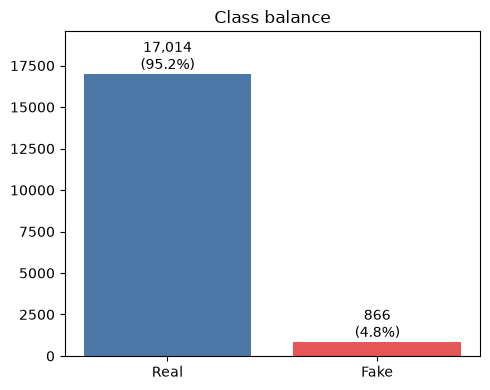

In [371]:
counts = df[Y].value_counts().sort_index()
print(counts)
print()
print(df[Y].value_counts(normalize=True).round(4))

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Real", "Fake"], counts.values, color=[C_REAL, C_FAKE])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom")
ax.set_title("Class balance"); ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout(); plt.show()

## 3. Missing data
Most columns have gaps. `salary_range` is missing **84%** of the time, `department` **65%**, `required_education` **45%**, and `benefits` **40%**.

Missing values are only informative in one column:
- **`company_profile`** is missing in **18% of fake postings versus 2% of real ones**. Scammers rarely have a real company to describe.

In [372]:
null_counts = df.isnull().sum()
null_pct = (df.isnull().mean() * 100).round(1)
pd.DataFrame({"missing": null_counts, "missing_%": null_pct}).sort_values("missing", ascending=False)

,missing,missing_%
salary_range,15012,84.0
department,11547,64.6
required_education,8105,45.3
benefits,7212,40.3
required_experience,7050,39.4
function,6455,36.1
industry,4903,27.4
employment_type,3471,19.4
company_profile,3308,18.5
requirements,2696,15.1


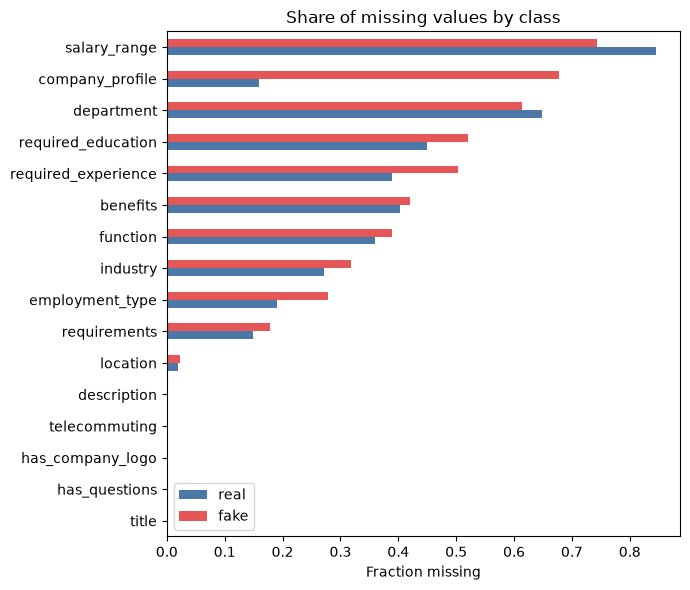

In [373]:
cols = [c for c in df.columns if c not in ("job_id", Y)]
miss = pd.DataFrame({
    "real": df[df[Y] == 0][cols].isnull().mean(),
    "fake": df[df[Y] == 1][cols].isnull().mean(),
}).sort_values("fake", ascending=True)

miss.plot.barh(figsize=(7, 6), color=[C_REAL, C_FAKE])
plt.title("Share of missing values by class"); plt.xlabel("Fraction missing")
plt.tight_layout(); plt.show()

In [374]:
# Fraud rate when a column is missing vs present
rows = []
text_cols_all = ['location','department','salary_range','company_profile','description','requirements',
                 'benefits','employment_type','required_experience','required_education','industry','function']
for c in text_cols_all:
    m = df[c].isnull()
    rows.append({"column": c,
                 "fraud_rate_if_missing": df[m][Y].mean() if m.any() else np.nan,
                 "fraud_rate_if_present": df[~m][Y].mean(),
                 "n_missing": int(m.sum())})
pd.DataFrame(rows).round(3).set_index("column")

,fraud_rate_if_missing,fraud_rate_if_present,n_missing
column,,,
location,0.055,0.048,346
department,0.046,0.053,11547
salary_range,0.043,0.078,15012
company_profile,0.177,0.019,3308
description,1.000,0.048,1
requirements,0.057,0.047,2696
benefits,0.050,0.047,7212
employment_type,0.069,0.043,3471
required_experience,0.062,0.040,7050


## 4. Strongest signals

| Signal | Fraud rate |
|---|---|
| No company logo | 15.9% (vs 2.0% with logo) |
| No company profile **and** no logo | **21.8%**, and this group holds **66% of all fraud** |
| No screening questions | 6.8% (vs 2.8%) |
| Telecommuting | 8.3% (vs 4.7%) |
| Part-time | 9.3% (vs 4.2% full-time) |
| Education "Some High School" | 74%, but only 27 rows |
| Industry: Oil & Energy / Accounting | 38% / 36% |
| Function: Administrative | 19% |
| Country: AU (214 rows) / US | 18.7% / 6.9%, versus under 1% for GB, DE, GR |

**Caveats:** several of the highest-rate groups (the education category, some industries) have small counts, so treat them cautiously. The country pattern may also reflect how the data was collected, not real fraud geography, so a model could end up learning the dataset's quirks.

In [375]:
for c in ["telecommuting", "has_company_logo", "has_questions"]:
    print(f"--- {c}")
    print(df.groupby(c)[Y].agg(["mean", "count"]).round(4))
    print()

--- telecommuting
                 mean  count
telecommuting               
0              0.0469  17113
1              0.0834    767

--- has_company_logo
                    mean  count
has_company_logo               
0                 0.1593   3660
1                 0.0199  14220

--- has_questions
                 mean  count
has_questions               
0              0.0678   9088
1              0.0284   8792



In [376]:
for c in ["employment_type", "required_experience", "required_education"]:
    print(f"--- {c}")
    print(df.groupby(c, dropna=False)[Y].agg(["mean", "count"]).sort_values("count", ascending=False).round(4))
    print()

--- employment_type
                   mean  count
employment_type               
Full-time        0.0422  11620
NaN              0.0694   3471
Contract         0.0289   1524
Part-time        0.0928    797
Temporary        0.0083    241
Other            0.0661    227

--- required_experience
                       mean  count
required_experience               
NaN                  0.0617   7050
Mid-Senior level     0.0297   3809
Entry level          0.0664   2697
Associate            0.0183   2297
Not Applicable       0.0538   1116
Director             0.0437    389
Internship           0.0262    381
Executive            0.0709    141

--- required_education
                                     mean  count
required_education                              
NaN                                0.0556   8105
Bachelor's Degree                  0.0194   5145
High School or equivalent          0.0817   2080
Unspecified                        0.0437   1397
Master's Degree                    0.07

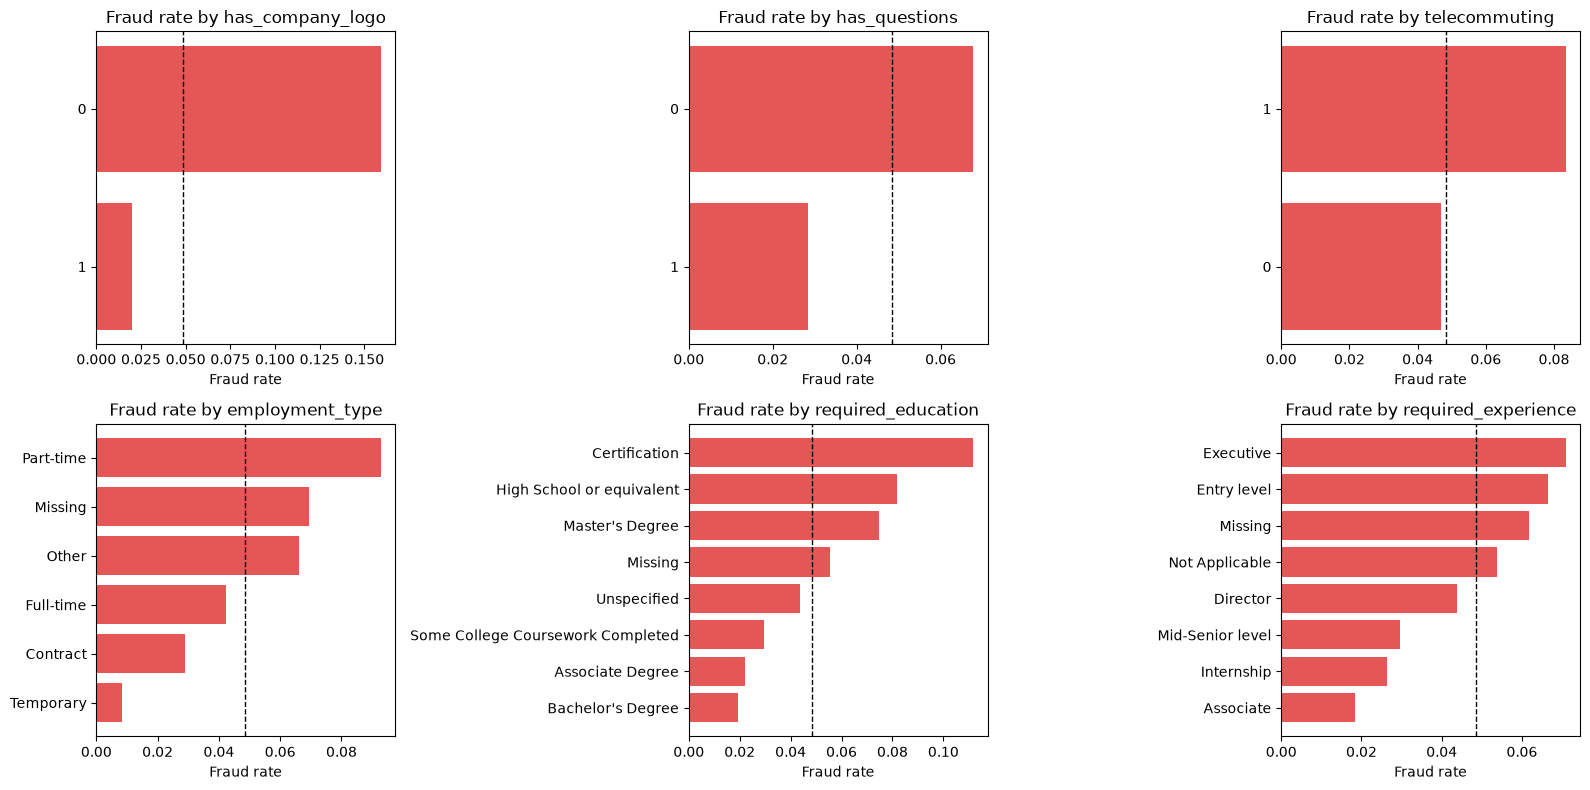

In [377]:
def rate_plot(ax, col, min_n=100, top=None):
    g = df.groupby(col, dropna=False)[Y].agg(["mean", "count"])
    g = g[g["count"] >= min_n].sort_values("mean", ascending=False)
    if top: g = g.head(top)
    g.index = g.index.fillna("Missing").astype(str)
    ax.barh(g.index[::-1], g["mean"][::-1], color=C_FAKE)
    ax.axvline(df[Y].mean(), color="k", ls="--", lw=1)
    ax.set_title(f"Fraud rate by {col}"); ax.set_xlabel("Fraud rate")

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(),
    ["has_company_logo", "has_questions", "telecommuting",
     "employment_type", "required_education", "required_experience"]):
    rate_plot(ax, c)
plt.tight_layout(); plt.show()

In [378]:
# Industry / function / country tables (groups with >= 50 postings)
df["country"] = df["location"].str.split(",").str[0].str.strip()

for c in ["industry", "function"]:
    g = df.groupby(c)[Y].agg(["mean", "count"])
    g = g[g["count"] >= 50].sort_values("mean", ascending=False)
    print(f"--- {c} (top 8 by fraud rate, n >= 50)")
    print(g.head(8).round(3)); print()

g = df.groupby("country")[Y].agg(["mean", "count"])
print("--- country (top 10 by fraud rate, n >= 100)")
print(g[g["count"] >= 100].sort_values("mean", ascending=False).head(10).round(3))
print()
print("Most common countries:"); print(df["country"].value_counts().head(8))

--- industry (top 8 by fraud rate, n >= 50)
                               mean  count
industry                                  
Oil & Energy                  0.380    287
Accounting                    0.358    159
Leisure, Travel & Tourism     0.276     76
Hospitality                   0.159     88
Real Estate                   0.137    175
Health, Wellness and Fitness  0.118    127
Hospital & Health Care        0.103    497
Telecommunications            0.076    342

--- function (top 8 by fraud rate, n >= 50)
                       mean  count
function                          
Administrative        0.189    630
Accounting/Auditing   0.137    212
Other                 0.098    325
Finance               0.087    172
Engineering           0.084   1348
Business Development  0.057    228
Advertising           0.056     90
Project Management    0.055    183

--- country (top 10 by fraud rate, n >= 100)
          mean  count
country              
AU       0.187    214
US       0.069  106

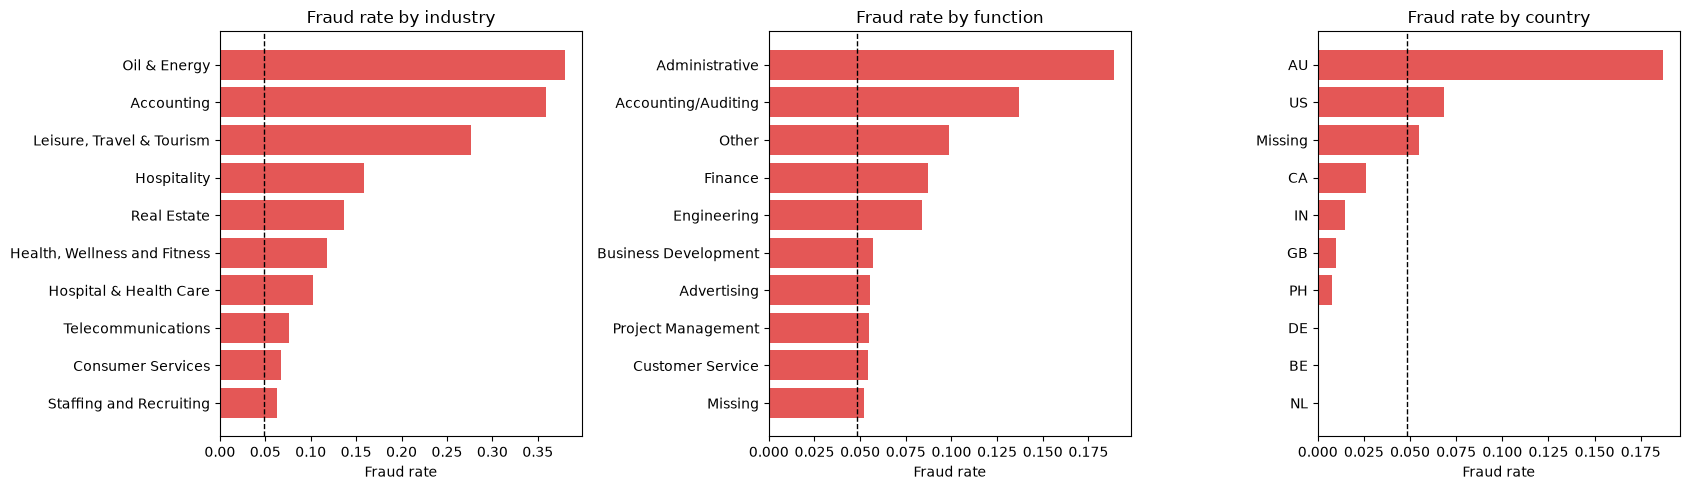

In [379]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
rate_plot(axes[0], "industry", min_n=75, top=10)
rate_plot(axes[1], "function", min_n=75, top=10)
rate_plot(axes[2], "country", min_n=100, top=10)
plt.tight_layout(); plt.show()

### Combined "ghost company" signal
Postings with **no company profile and no company logo** are a small slice of the data but contain most of the fraud.

In [380]:
ghost = df["company_profile"].isnull() & (df["has_company_logo"] == 0)
print(f"No profile & no logo: {ghost.sum()} rows")
print(f"Fraud rate in this group: {df[ghost][Y].mean():.1%}")
print(f"Share of ALL fraud captured: {df[ghost][Y].sum() / df[Y].sum():.1%}")

No profile & no logo: 2622 rows
Fraud rate in this group: 21.8%
Share of ALL fraud captured: 66.1%


## 5. Text findings

- **Fake postings are shorter.** The median company profile is **0 words for fake vs 86 for real**, and requirements are **34 vs 63 words**. The median combined text is **224 vs 355 words**.
- **Words over-represented in fake postings** are the classic "easy work" vocabulary: *earn, home, entry, encouraged, typing, bonuses, administrative, needed, staffing*.
- **Words over-represented in real postings** are culture and tech language: *team, growing, passionate, love, creative, software, web*.
- The text contains anonymised placeholder tokens like `#URL_xxxx#`. They are stripped for the word analysis.

In [381]:
text_cols = ["company_profile", "description", "requirements", "benefits"]
rows = []
for c in text_cols:
    L = df[c].fillna("").str.split().str.len()
    rows.append({"field": c,
                 "median_real": L[df[Y] == 0].median(), "median_fake": L[df[Y] == 1].median(),
                 "mean_real": round(L[df[Y] == 0].mean(), 1), "mean_fake": round(L[df[Y] == 1].mean(), 1)})
pd.DataFrame(rows).set_index("field")

,median_real,median_fake,mean_real,mean_fake
field,,,,
company_profile,86.0,0.0,95.7,31.7
description,147.0,113.5,171.0,158.7
requirements,63.0,34.0,79.0,58.4
benefits,6.0,5.0,30.0,29.5


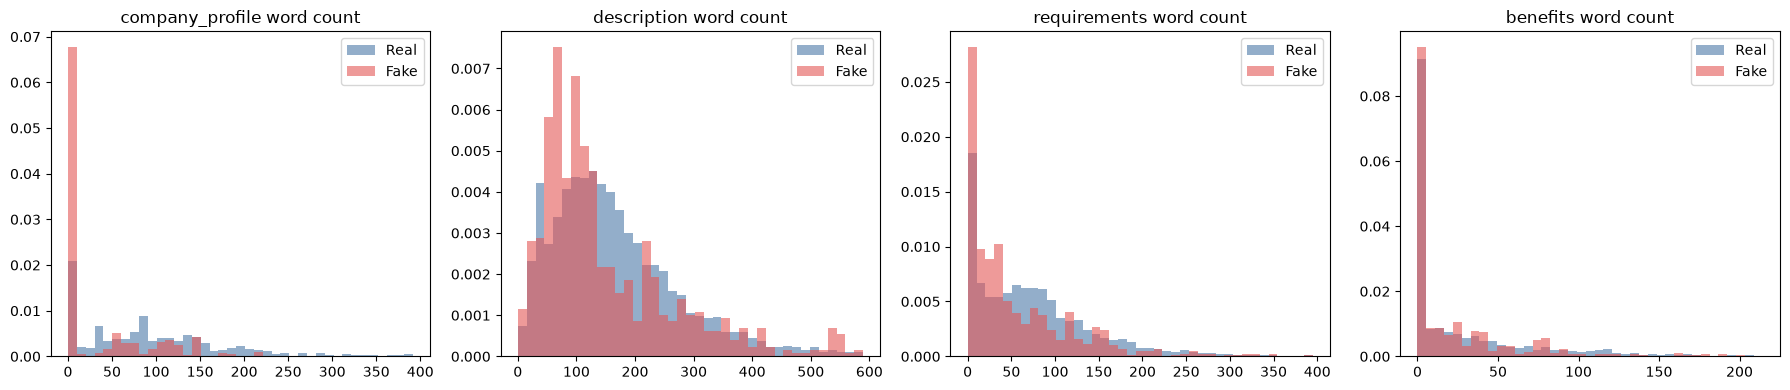

In [382]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, text_cols):
    L = df[c].fillna("").str.split().str.len()
    bins = np.linspace(0, L.quantile(0.99), 40)
    ax.hist(L[df[Y] == 0], bins=bins, alpha=.6, density=True, color=C_REAL, label="Real")
    ax.hist(L[df[Y] == 1], bins=bins, alpha=.6, density=True, color=C_FAKE, label="Fake")
    ax.set_title(f"{c} word count"); ax.legend()
plt.tight_layout(); plt.show()

In [383]:
# Combined text (cleaned): title + profile + description + requirements + benefits
txt = (df["title"].fillna("") + " " + df["company_profile"].fillna("") + " " +
       df["description"].fillna("") + " " + df["requirements"].fillna("") + " " +
       df["benefits"].fillna(""))
txt = (txt.str.replace(r"#(URL|EMAIL|PHONE)_[a-z0-9]+#", " ", regex=True)
          .str.replace(r"<[^>]+>", " ", regex=True))

wc = txt.str.split().str.len()
print("Median combined word count by class:", wc.groupby(df[Y]).median().to_dict())
print("Mean title length (chars) by class:", df["title"].str.len().groupby(df[Y]).mean().round(1).to_dict())

Median combined word count by class: {0: 355.0, 1: 224.0}
Mean title length (chars) by class: {0: 28.4, 1: 30.7}


Fake-heavy words (word, share in fake, share in real):
[('earn', 0.169, 0.016), ('000', 0.23, 0.078), ('entry', 0.207, 0.057), ('home', 0.237, 0.097), ('encouraged', 0.143, 0.011), ('needed', 0.236, 0.11), ('staffing', 0.157, 0.038), ('area', 0.212, 0.096), ('position', 0.428, 0.312), ('participate', 0.162, 0.054), ('benefits', 0.35, 0.245), ('corporate', 0.179, 0.075), ('oil', 0.121, 0.021), ('duties', 0.247, 0.148), ('administrative', 0.148, 0.049)]

Real-heavy words (word, share in fake, share in real):
[('team', 0.446, 0.697), ('growing', 0.05, 0.292), ('help', 0.219, 0.407), ('web', 0.069, 0.254), ('world', 0.129, 0.302), ('new', 0.328, 0.487), ('love', 0.027, 0.183), ('passionate', 0.017, 0.173), ('best', 0.151, 0.305), ('experience', 0.671, 0.824), ('based', 0.248, 0.395), ('software', 0.129, 0.275), ('companies', 0.121, 0.267), ('creative', 0.038, 0.183), ('want', 0.061, 0.204)]


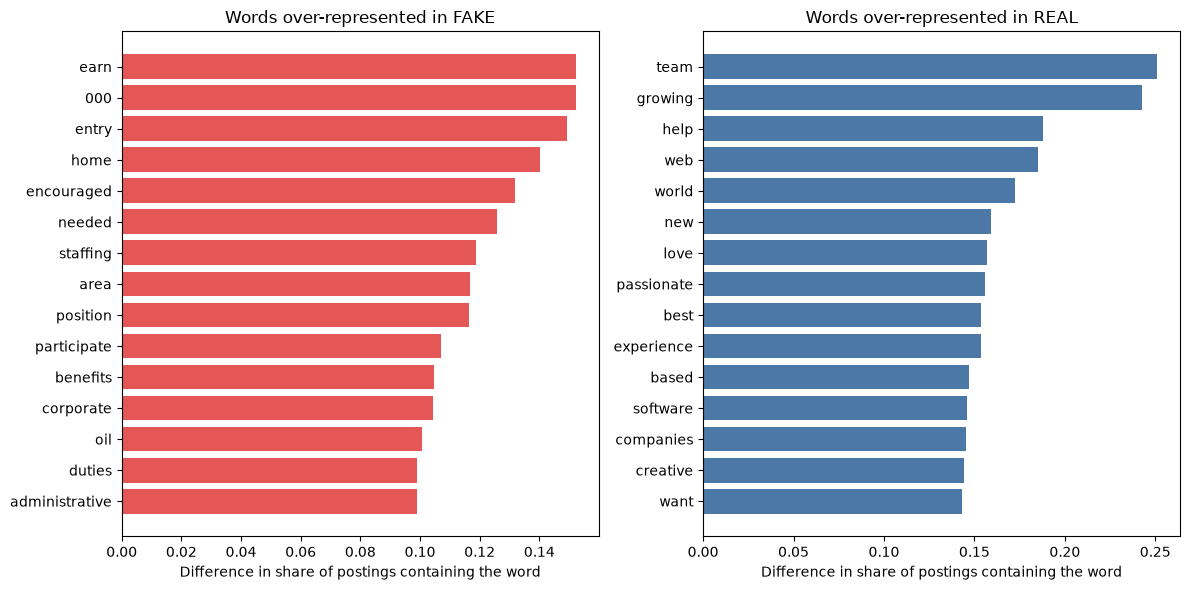

In [384]:
cv = CountVectorizer(stop_words="english", min_df=20, binary=True, max_features=20000)
X = cv.fit_transform(txt).tocsr()
vocab = np.array(cv.get_feature_names_out())
lab = df[Y].values
f = np.asarray(X[np.where(lab == 1)[0]].mean(0)).ravel()   # share of FAKE postings containing the word
r = np.asarray(X[np.where(lab == 0)[0]].mean(0)).ravel()   # share of REAL postings containing the word
diff = f - r

top_f, top_r = np.argsort(-diff)[:15], np.argsort(diff)[:15]

print("Fake-heavy words (word, share in fake, share in real):")
print([(vocab[i], round(float(f[i]), 3), round(float(r[i]), 3)) for i in top_f])
print()
print("Real-heavy words (word, share in fake, share in real):")
print([(vocab[i], round(float(f[i]), 3), round(float(r[i]), 3)) for i in top_r])

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].barh(vocab[top_f][::-1], diff[top_f][::-1], color=C_FAKE); axes[0].set_title("Words over-represented in FAKE")
axes[1].barh(vocab[top_r][::-1], -diff[top_r][::-1], color=C_REAL); axes[1].set_title("Words over-represented in REAL")
for a in axes: a.set_xlabel("Difference in share of postings containing the word")
plt.tight_layout(); plt.show()

In [385]:
# A few fake titles, to get a feel for them
print(df[df[Y] == 1]["title"].sample(8, random_state=1).tolist())

['Clinical Director - Surgical Services  ', 'Subsea Process System Engineer', 'Sales Professional- SMB Division ', 'Marketing Database Decision Strategy Consultant ', 'Administrative Manager', 'Admin Clerk Remote Position', 'SAP Support Advisor', 'Sales professionals']


## 6. Data quality issues to handle before modeling

1. **Duplicates:** 4,268 rows share a description with another row. Of the 1,190 duplicated descriptions, only one has conflicting labels. If duplicates land on both sides of your train/test split, your scores will be inflated, so split by description or deduplicate first.
2. **One row has a missing description**, and it is labelled fake.
3. **Pay information:** nearly all `salary_range` values are numeric `min-max` strings, so they can be parsed into numeric features.
4. **Dollar amounts in the text** (`$` followed by a digit) appear in 11.9% of postings, and 10.7% of those are fake, versus 4.1% of postings without one. That's a cheap engineered feature.

In [386]:
# 1. Duplicates
d = df[df["description"].notnull()]
grp = d.groupby("description")[Y].agg(["count", "nunique", "mean"])
print("Duplicate-description groups:", (grp["count"] > 1).sum(),
      "| groups with conflicting labels:", (grp["nunique"] > 1).sum(),
      "| groups that are entirely fraud:", ((grp["count"] > 1) & (grp["mean"] == 1)).sum())
print("Rows that share a description with another row:", df["description"].duplicated(keep=False).sum())
dup_rows = df[df["description"].notnull() & df["description"].duplicated(keep=False)]
print(f"Fraud rate within duplicated-description rows: {dup_rows[Y].mean():.3f}")
print("Duplicate descriptions (extra copies):", df["description"].duplicated().sum(),
      "| Duplicate titles (extra copies):", df["title"].duplicated().sum())
print()
print("Most common titles:"); print(df["title"].value_counts().head(5))

Duplicate-description groups: 1190 | groups with conflicting labels: 1 | groups that are entirely fraud: 80
Rows that share a description with another row: 4268
Fraud rate within duplicated-description rows: 0.074
Duplicate descriptions (extra copies): 3078 | Duplicate titles (extra copies): 6649

Most common titles:
title
English Teacher Abroad                                311
Customer Service Associate                            146
Graduates: English Teacher Abroad (Conversational)    144
English Teacher Abroad                                 95
Software Engineer                                      86
Name: count, dtype: int64


In [387]:
# 2. Missing description
print("Rows with missing description:", df["description"].isnull().sum())
print("Their labels:", df[df["description"].isnull()][Y].tolist())

Rows with missing description: 1
Their labels: [1]


In [388]:
# 3. Salary range
print(df["salary_range"].dropna().head(8).tolist())
print()
print("Share of non-null salary_range values in 'min-max' format:",
      round(df["salary_range"].dropna().str.contains("-").mean(), 4))
print()
print("Fraud rate by salary_range present?")
print(df.groupby(df["salary_range"].notnull())[Y].mean().rename({False: "missing", True: "present"}).round(4))

['20000-28000', '100000-120000', '120000-150000', '100000-120000', '50000-65000', '40000-50000', '60-80', '65000-70000']

Share of non-null salary_range values in 'min-max' format: 0.9997

Fraud rate by salary_range present?
salary_range
missing    0.0428
present    0.0778
Name: fraudulent, dtype: float64


In [389]:
# 4. Regex-based text signals (searched in company_profile + description + requirements)
raw = (df["description"].fillna("") + " " + df["requirements"].fillna("") + " " + df["company_profile"].fillna(""))
patterns = [("url", r"https?://|www\."),
            ("email", r"[\w.]+@[\w.]+"),
            ("#URL_ token", r"#URL_"),
            ("html tag", r"<[a-z]+"),
            ("money ($ + digit)", r"\$\d"),
            ("ALLCAPS word (5+ letters)", r"\b[A-Z]{5,}\b")]
rows = []
for name, pat in patterns:
    flag = raw.str.contains(pat, regex=True)
    rows.append({"signal": name, "share_of_postings": round(flag.mean(), 3),
                 "fraud_rate_if_present": round(df[flag][Y].mean(), 3) if flag.any() else np.nan,
                 "fraud_rate_if_absent": round(df[~flag][Y].mean(), 3)})
pd.DataFrame(rows).set_index("signal")

,share_of_postings,fraud_rate_if_present,fraud_rate_if_absent
signal,,,
url,0.008,0.007,0.049
email,0.001,0.000,0.048
#URL_ token,0.297,0.046,0.050
html tag,0.000,NaN,0.048
money ($ + digit),0.119,0.107,0.041
ALLCAPS word (5+ letters),0.280,0.052,0.047


## 7. Suggested next steps for the project
1. Combine the text columns into one field and clean it (HTML, placeholder tokens, lowercasing).
2. Build a **TF-IDF + Logistic Regression** baseline with a **stratified, deduplicated split** and `class_weight='balanced'`.
3. Add the structured features: missing-profile flag, logo, questions, text lengths and parsed salary.
4. Compare against a transformer (**DistilBERT**) only after you have the baseline numbers.

In [390]:
df.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent,country
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaking and award-winning cooking s...","Food52, a fast-growing, James Beard Award-winning online food community and ...",Experience with content management systems a major plus (any blogging counts...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0,US
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production Service.90 Seconds is the worl...",Organised - Focused - Vibrant - Awesome!Do you have a passion for customer s...,What we expect from you:Your key responsibility will be to communicate with ...,What you will get from usThrough being part of the 90 Seconds team you will ...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0,NZ
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions that meet the needs of companies...,"Our client, located in Houston, is actively seeking an experienced Commissio...",Implement pre-commissioning and commissioning procedures for rotary equipmen...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0,US
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life through geography is at the heart ...,THE COMPANY: ESRI – Environmental Systems Research InstituteOur passion for ...,"EDUCATION: Bachelor’s or Master’s in GIS, business administration, or a rela...","Our culture is anything but corporate—we have a collaborative, creative envi...",0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0,US
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Capital Management Consulting fir...,"JOB TITLE: Itemization Review ManagerLOCATION: Fort Worth, TX ...",QUALIFICATIONS:RN license in the State of TexasDiploma or Bachelors of Scien...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0,US


## Corpus Creation and dropping columns

In [391]:
df['corpus'] = df['company_profile'].fillna("")+ " " + df['description'].fillna("")+ " " + df['requirements'].fillna("")+ " " + df['benefits'].fillna('')+ " "+ df['title']
df.drop(columns=['job_id', 'location', 'company_profile' ,'description', 'requirements' ,'benefits', 'department', 'function' , 'title', 'salary_range', 'country','industry'], inplace=True)
df.head()

,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,fraudulent,corpus
0,0,1,0,Other,Internship,NaN,0,"We're Food52, and we've created a groundbreaking and award-winning cooking s..."
1,0,1,0,Full-time,Not Applicable,NaN,0,"90 Seconds, the worlds Cloud Video Production Service.90 Seconds is the worl..."
2,0,1,0,NaN,NaN,NaN,0,Valor Services provides Workforce Solutions that meet the needs of companies...
3,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,0,Our passion for improving quality of life through geography is at the heart ...
4,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,0,SpotSource Solutions LLC is a Global Human Capital Management Consulting fir...


## Working with null values

In [392]:
df.isnull().sum()

telecommuting             0
has_company_logo          0
has_questions             0
employment_type        3471
required_experience    7050
required_education     8105
fraudulent                0
corpus                    0
dtype: int64

In [404]:
cat_cols = df[['employment_type', 'required_experience', 'required_education']].columns.tolist()
num_cols = df[['telecommuting', 'has_company_logo', 'has_questions']].columns.tolist()

print(cat_cols)
print(num_cols)

['employment_type', 'required_experience', 'required_education']
['telecommuting', 'has_company_logo', 'has_questions']


In [ ]:
#filling values in categorical col
for col in cat_cols:
    df[col] = df[col].fillna('Unknown')

## Data Preprocessing

## Splitting 

In [407]:
X = df[['corpus'] + cat_cols + num_cols]
y = df['fraudulent']

display(X)
display(y)

,corpus,employment_type,required_experience,required_education,telecommuting,has_company_logo,has_questions
0,"We're Food52, and we've created a groundbreaking and award-winning cooking s...",Other,Internship,Unknown,0,1,0
1,"90 Seconds, the worlds Cloud Video Production Service.90 Seconds is the worl...",Full-time,Not Applicable,Unknown,0,1,0
2,Valor Services provides Workforce Solutions that meet the needs of companies...,Unknown,Unknown,Unknown,0,1,0
3,Our passion for improving quality of life through geography is at the heart ...,Full-time,Mid-Senior level,Bachelor's Degree,0,1,0
4,SpotSource Solutions LLC is a Global Human Capital Management Consulting fir...,Full-time,Mid-Senior level,Bachelor's Degree,0,1,1
...,...,...,...,...,...,...,...
17875,Vend is looking for some awesome new talent to come join us. You'll be worki...,Full-time,Mid-Senior level,Unknown,0,1,1
17876,WebLinc is the e-commerce platform and services provider for the fastest gro...,Full-time,Mid-Senior level,Bachelor's Degree,0,1,1
17877,We Provide Full Time Permanent Positions for many medium to large US compani...,Full-time,Unknown,Unknown,0,0,0
17878,Nemsia Studios is looking for an experienced visual/graphic designer to joi...,Contract,Not Applicable,Professional,0,0,1


0        0
1        0
2        0
3        0
4        0
        ..
17875    0
17876    0
17877    0
17878    0
17879    0
Name: fraudulent, Length: 17880, dtype: int64

## Train test aplit

In [409]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(14304, 7)
(3576, 7)
(14304,)
(3576,)


## ColumnTransformer : different processing for different columns
making columntransformer for preprocessing data

In [414]:
preprocessor = ColumnTransformer(transformers=[
    ('text', CountVectorizer(), 'corpus'),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('num', 'passthrough', num_cols)
])

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('text', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_

## PipeLines for Model Training

In [418]:
model = Pipeline([
    ("prep", preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))    
])

model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['corpus','employment_type','required_experience',...,'telecommuting', 'has_company_logo','has_questions']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('text', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifyi

## Evaluation

In [419]:
y_pred = model.predict(X_test)

print('Accuracy : ', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy :  0.9793064876957495
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3395
           1       0.77      0.83      0.80       181

    accuracy                           0.98      3576
   macro avg       0.88      0.91      0.90      3576
weighted avg       0.98      0.98      0.98      3576



## XGboost 

## Saving model

In [ ]:
joblib.dump(model, 'fake_job_post_detector_model.pkl')

['fake_job_post_detector_model.pkl']